# Request GOOS passport data

This notebook shows how to request all passport data from GOOS for a given WMO ID.

**Should work for all GOOS platforms**

In [1]:
import requests
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

### Authentication

The GOOS API requires authentication, see the [API token guide](https://www.ocean-ops.org/passports/#/tokens)

You can add your auth in a file `secrets.json` in the home directory of this repo, or directly in the cell below

In [2]:
oceanops_auth = {'X-OceanOPS-Metadata-ID': 'nnnn',
 'X-OceanOPS-Metadata-Token': '16-char-secret-token'}

if Path('../secrets.json').exists():
    with open('../secrets.json') as f:
        oceanops_auth = json.load(f)
else:
    print("enter your oceanOPS authentication in the dictionary `oceanops_auth` in this cell")

### Use WMO ID of glider to get all OceanOPS passports info on that platform

**update the wmo_id below to one of your platforms**

We enumerate through the potential passport IDs for a given wmo_id until the API returns a 404

In [3]:
wmo_id = 6801674
wigos_ids = [f'0-22000-{num}-{wmo_id}' for num in range(1000)]
headers = {
    'Content-Type': 'application/json',
    'accept': 'application/json',
    **oceanops_auth
}
output_dir = Path('output')
if not output_dir.exists():
    output_dir.mkdir()

In [4]:
oceanops_info = {}

for wigos_id in wigos_ids:
    _, _, passport_num, _ = wigos_id.split('-')
    url = f'https://www.ocean-ops.org/api/data/platforms/{wigos_id}'
    response = requests.patch(url, headers=headers, json={})
    if response.status_code == 404:
        print(f"SUCCESS Maxed out at passport id {wigos_id} which does not exist. Total number of existing wigos IDs for this platform {wmo_id}: {passport_num}")
        break
    elif response.status_code==200:
        resp_json = response.json()
        oceanops_info[wigos_id] = resp_json
    else:
        print(f"FAIL Request returned unexpected status code {response.status_code}")
        print(response.content)
        break


SUCCESS Maxed out at passport id 0-22000-34-6801674 which does not exist. Total number of existing wigos IDs for this platform 6801674: 34


We flatten these dictionaries of data into a single pandata DataFrame. This summarises all the data OceanOPS currently has in the passports for this platform

In [5]:
oceanops_info_flat = {}
for dataset_id, ddict in oceanops_info.items():
    _, _, passport_num, _ = ddict['wigosId'].split('-')
    flat_ddict = {'passport_num': int(passport_num)}
    for key, val in ddict.items():
        if type(val) != dict:
            flat_ddict[key] = val
            continue
        for sub_key, sub_val in val.items():
            flat_ddict[f'{key}_{sub_key}'] = str(sub_val)
    oceanops_info_flat[dataset_id] = flat_ddict
df_oceanops = pd.DataFrame(oceanops_info_flat).T
for col in df_oceanops.columns:
    if 'date' in col.lower():
        df_oceanops[col] = pd.to_datetime(df_oceanops[col])
if 'deployment_date' in list(df_oceanops):
    df_oceanops = df_oceanops.sort_values(by='deployment_date')
df_oceanops.head()

,passport_num,id,wigosId,name,comments,deployment_date,deployment_latitude,deployment_longitude,deployment_ship,retrieval_startDate,retrieval_endDate,retrieval_endingCause,identification_internalId,telecom_type,hardware_mainDevice,affiliation_program,affiliation_networks
0-22000-0-6801674,0,1145835,0-22000-0-6801674,Kaprifol,"raw, uncorrected salinity<br/>This study used ...",2020-10-31 09:03:00+00:00,55.5654296875,15.693249702453613,"{'imoNumber': '7012179', 'ovhId': '1015198'}",2020-11-19 10:00:30+00:00,2020-11-19 10:00:30+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",Kaprifol55-20201031T0902,{'code': 'iridium'},"{'model': {'code': 'seaexplorer'}, 'serialNumb...",{'code': 'voto-ocean-knowledge-glider-program'},"['boon', 'eoos', 'marginal-seas', 'oceanglider..."
0-22000-1-6801674,1,1145836,0-22000-1-6801674,Kaprifol,"raw, uncorrected salinity<br/>This study used ...",2021-03-05 08:13:31+00:00,55.57067108154297,16.365665435791016,"{'imoNumber': '7012179', 'ovhId': '1015198'}",2021-03-25 11:39:00+00:00,2021-03-25 11:39:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",Kaprifol55-20210305T0813,{'code': 'iridium'},"{'model': {'code': 'seaexplorer'}, 'serialNumb...",{'code': 'voto-ocean-knowledge-glider-program'},"['boon', 'eoos', 'marginal-seas', 'oceanglider..."
0-22000-2-6801674,2,1145837,0-22000-2-6801674,Kaprifol,"raw, uncorrected salinity<br/>This study used ...",2021-03-26 09:38:30+00:00,55.57067108154297,16.351533889770508,"{'imoNumber': '7012179', 'ovhId': '1015198'}",2021-04-14 04:46:00+00:00,2021-04-14 04:46:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",Kaprifol55-20210326T0938,{'code': 'iridium'},"{'model': {'code': 'seaexplorer'}, 'serialNumb...",{'code': 'voto-ocean-knowledge-glider-program'},"['boon', 'eoos', 'marginal-seas', 'oceanglider..."
0-22000-3-6801674,3,1145838,0-22000-3-6801674,Kaprifol,"raw, uncorrected salinity<br/>This study used ...",2021-04-14 17:13:03+00:00,55.57075119018555,16.35016632080078,"{'imoNumber': '7012179', 'ovhId': '1015198'}",2021-05-02 16:11:30+00:00,2021-05-02 16:11:30+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",Kaprifol55-20210414T1713,{'code': 'iridium'},"{'model': {'code': 'seaexplorer'}, 'serialNumb...",{'code': 'voto-ocean-knowledge-glider-program'},"['boon', 'eoos', 'marginal-seas', 'oceanglider..."
0-22000-4-6801674,4,1145839,0-22000-4-6801674,Kaprifol,"raw, uncorrected salinity<br/>This study used ...",2021-05-03 06:19:00+00:00,55.57124710083008,16.351551055908203,"{'imoNumber': '7012179', 'ovhId': '1015198'}",2021-05-21 14:57:00+00:00,2021-05-21 14:57:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",Kaprifol55-20210503T0609,{'code': 'iridium'},"{'model': {'code': 'seaexplorer'}, 'serialNumb...",{'code': 'voto-ocean-knowledge-glider-program'},"['boon', 'eoos', 'marginal-seas', 'oceanglider..."


Let's print a more digestible version of that table

In [6]:
subset = set(list(df_oceanops)).intersection(['passport_num',  'name',  'deployment_date', 'deployment_latitude', 'deployment_longitude', 'retrieval_startDate', 'retrieval_endDate', 'retrieval_endingCause', ])
df_oceanops[list(subset)].head()


,retrieval_startDate,deployment_longitude,passport_num,retrieval_endDate,retrieval_endingCause,deployment_date,deployment_latitude,name
0-22000-0-6801674,2020-11-19 10:00:30+00:00,15.693249702453613,0,2020-11-19 10:00:30+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",2020-10-31 09:03:00+00:00,55.5654296875,Kaprifol
0-22000-1-6801674,2021-03-25 11:39:00+00:00,16.365665435791016,1,2021-03-25 11:39:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",2021-03-05 08:13:31+00:00,55.57067108154297,Kaprifol
0-22000-2-6801674,2021-04-14 04:46:00+00:00,16.351533889770508,2,2021-04-14 04:46:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",2021-03-26 09:38:30+00:00,55.57067108154297,Kaprifol
0-22000-3-6801674,2021-05-02 16:11:30+00:00,16.35016632080078,3,2021-05-02 16:11:30+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",2021-04-14 17:13:03+00:00,55.57075119018555,Kaprifol
0-22000-4-6801674,2021-05-21 14:57:00+00:00,16.351551055908203,4,2021-05-21 14:57:00+00:00,"{'code': 'voluntary-recovery-of-the-platform',...",2021-05-03 06:19:00+00:00,55.57124710083008,Kaprifol


3. Plot temporal extent of passports

Passports with start and end date show as lines, those with only start date are circles, those with only recovery date are squares

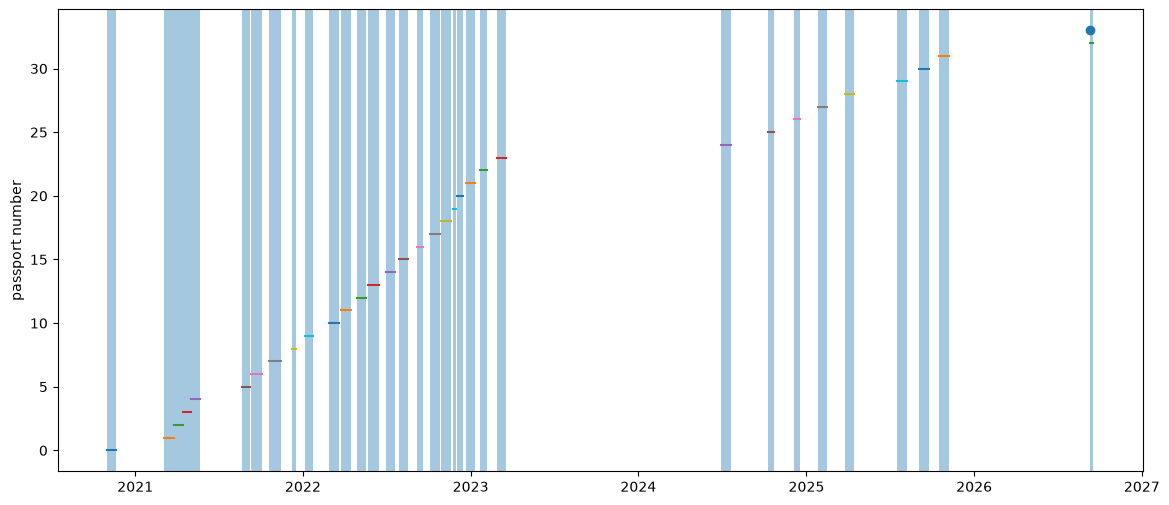

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))
for i, row in df_oceanops.iterrows():
    if 'deployment_date' in row.keys() and 'retrieval_startDate' in row.keys():
        if not pd.isnull(row.deployment_date) and not pd.isnull(row.retrieval_startDate):
            ax.axvspan(row.deployment_date, row.retrieval_startDate, alpha=0.4)

            ax.plot((row.deployment_date, row.retrieval_startDate), (row.passport_num, row.passport_num))
            continue
    if not pd.isnull(row.deployment_date):
        ax.scatter((row.deployment_date, ), (row.passport_num))
        continue
    ax.scatter((row.retrieval_startDate, ), (row.passport_num), marker='s')
ax.set(ylabel='passport number');

### Save output

We save this info that GOOS has in a table for later use

In [8]:
df_oceanops.to_csv(output_dir / f'goos_data_{wmo_id}.csv', index=False)

To update the info GOOS has on your platform, see the following notebooks